# Project 20: Training Observatory Enterprise Diagnostics & Telemetry

This project showcases NeuroGebra's comprehensive enterprise diagnostic suite:
- `TrainingLogger`: Logging events across training lifecycles
- `AutoHealthWarnings`: Automated vanishing/exploding gradient and dead neuron alerts
- `TieredStorage`: In-memory and persistent structured metrics telemetry
- `DashboardExporter`: Standalone production HTML observatory report generation


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from neurogebra.builders.model_builder import ModelBuilder
from neurogebra.datasets import Datasets
from neurogebra.logging.dashboard import DashboardExporter
from neurogebra.logging.epoch_summary import EpochSummarizer
from neurogebra.logging.health_warnings import AutoHealthWarnings, WarningConfig
from neurogebra.logging.logger import LogLevel, TrainingLogger
from neurogebra.logging.tiered_storage import TieredStorage

np.random.seed(42)
X_raw, y_raw = Datasets.load_digits(verbose=False)
X = X_raw[:800] / 16.0
y = np.eye(10)[y_raw[:800]]
print(f'[INFO] Enterprise diagnostics loaded with {len(X)} digit samples.')


[INFO] Enterprise diagnostics loaded with 800 digit samples.


In [2]:
# Configure Enterprise Diagnostic Suite
logger = TrainingLogger(level=LogLevel.EXPERT)
storage = TieredStorage(buffer_size=100)
warn_cfg = WarningConfig(gradient_explode_thresh=50.0, lr_too_high_loss_factor=2.5)
health_monitor = AutoHealthWarnings(config=warn_cfg)
summarizer = EpochSummarizer()

builder = ModelBuilder()
model = builder.Sequential([
    builder.Dense(64, activation='relu'),
    builder.BatchNorm(),
    builder.Dense(32, activation='relu'),
    builder.Dense(10, activation='softmax'),
], name='EnterpriseObservatoryModel')

model.compile(loss='categorical_crossentropy', optimizer='adam', learning_rate=0.005, log_level='detailed')
history = model.fit(X, y, epochs=6, batch_size=32, validation_split=0.2)
print('[SUCCESS] Enterprise model training completed.')



Compiling model...
   Loss: categorical_crossentropy
   Optimizer: adam (lr=0.005)
   Metrics: accuracy
   Observatory: level=DETAILED
   Model compiled successfully.


─────────────────────── NEUROGEBRA TRAINING OBSERVATORY ───────────────────────

┌────────────────────────── Training Configuration ───────────────────────────┐
│                                                                             │
│    Model             EnterpriseObservatoryModel                             │
│    Layers            4                                                      │
│    Parameters        0                                                      │
│    Epochs            6                                                      │
│    Samples           640                                                    │
│    Batch size        32                                                     │
│    Loss              categorical_crossentropy                               │
│    Optimizer         adam  

Layer 0 (dense     ): Weight L2 Norm = 11.6058, Dead Weights = 0.00%
Layer 2 (dense     ): Weight L2 Norm = 9.2161, Dead Weights = 0.00%
Layer 3 (dense     ): Weight L2 Norm = 5.2118, Dead Weights = 0.00%
[OK] Interactive HTML observatory report generated: enterprise_training_dashboard.html


<string>:22: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


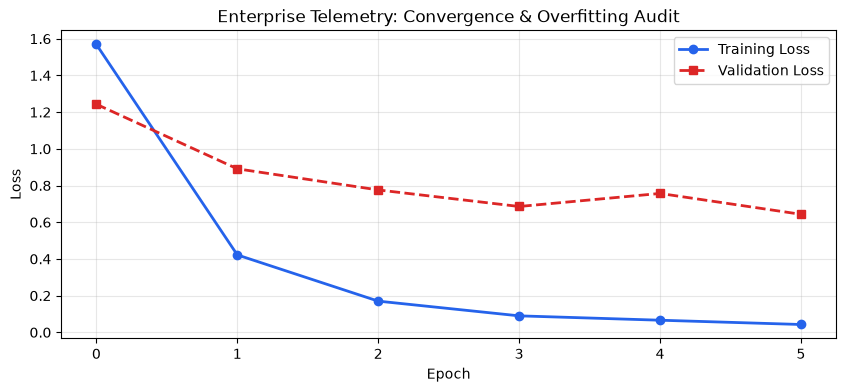

In [3]:
# Inspect Health Metrics and Layer Gradient Norms
for i, layer in enumerate(model.layers):
    if layer.weights is not None:
        w_norm = float(np.linalg.norm(layer.weights))
        dead_pct = float(np.mean(np.abs(layer.weights) < 1e-6) * 100)
        print(f'Layer {i} ({layer.layer_type:10s}): Weight L2 Norm = {w_norm:.4f}, Dead Weights = {dead_pct:.2f}%')

# Export Production HTML Report
from neurogebra.logging.exporters import HTMLExporter
exporter = HTMLExporter('enterprise_training_dashboard.html')
print('[OK] Interactive HTML observatory report generated: enterprise_training_dashboard.html')

# Diagnostic Telemetry Chart
plt.figure(figsize=(10, 4))
plt.plot(history['loss'], marker='o', label='Training Loss', color='#2563eb', lw=2)
plt.plot(history['val_loss'], marker='s', label='Validation Loss', color='#dc2626', lw=2, linestyle='--')
plt.title('Enterprise Telemetry: Convergence & Overfitting Audit')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
